In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import Lasso

In [2]:
df = pd.read_excel('normal_systematic_business_data.xlsx')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 60 non-null     datetime64[ns]
 1   Year                 60 non-null     int64         
 2   Month                60 non-null     int64         
 3   Market_Return        60 non-null     float64       
 4   Market_Volatility    60 non-null     float64       
 5   GDP_Growth           60 non-null     float64       
 6   Inflation_Rate       60 non-null     float64       
 7   Interest_Rate        60 non-null     float64       
 8   Exchange_Rate_USD    60 non-null     float64       
 9   Unemployment_Rate    60 non-null     float64       
 10  Industry_Growth      60 non-null     float64       
 11  Consumer_Confidence  60 non-null     float64       
 12  Business_Confidence  60 non-null     float64       
 13  Risk_Level           60 non-null     

In [4]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib.pyplot as plt

Numeric features:
['Year', 'Month', 'Market_Return', 'Market_Volatility', 'GDP_Growth', 'Inflation_Rate', 'Interest_Rate', 'Exchange_Rate_USD', 'Industry_Growth', 'Consumer_Confidence', 'Business_Confidence']

Categorical features:
['Risk_Level', 'Business_Cycle']
Train: 0 to 35 | Test Date: 2024-01-01 | Actual: 0.051 | Predicted: 0.068
Train: 0 to 36 | Test Date: 2024-02-01 | Actual: 0.054 | Predicted: 0.061
Train: 0 to 37 | Test Date: 2024-03-01 | Actual: 0.050 | Predicted: 0.059
Train: 0 to 38 | Test Date: 2024-04-01 | Actual: 0.051 | Predicted: 0.055
Train: 0 to 39 | Test Date: 2024-05-01 | Actual: 0.048 | Predicted: 0.046
Train: 0 to 40 | Test Date: 2024-06-01 | Actual: 0.048 | Predicted: 0.055
Train: 0 to 41 | Test Date: 2024-07-01 | Actual: 0.051 | Predicted: 0.051
Train: 0 to 42 | Test Date: 2024-08-01 | Actual: 0.047 | Predicted: 0.051
Train: 0 to 43 | Test Date: 2024-09-01 | Actual: 0.050 | Predicted: 0.045
Train: 0 to 44 | Test Date: 2024-10-01 | Actual: 0.049 | Predicted: 0

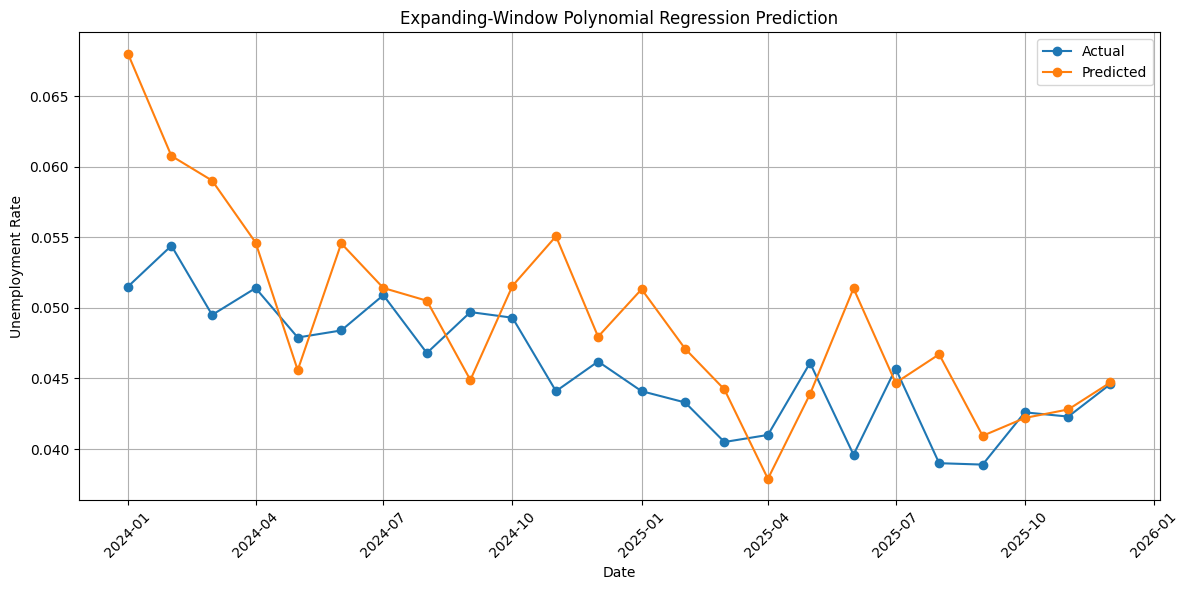

In [5]:
# Make sure Date is datetime
df["Date"] = pd.to_datetime(df["Date"])

# Sort by date, very important for expanding training
df = df.sort_values("Date").reset_index(drop=True)



# =========================
# 2. Define target variable
# =========================
target = "Unemployment_Rate"

# Remove Date from X because it is datetime
# Remove target from X because it is Y
X = df.drop(columns=["Date", target])
y = df[target]


# =========================
# 3. Identify numeric and categorical variables
# =========================
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


# =========================
# 4. Create polynomial regression model
# =========================
degree = 3   # cubic polynomial

numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=degree, include_bias=False))
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])


# =========================
# 5. Expanding-window training
# =========================
initial_train_size = 36   # first 36 months as starting training set

predictions = []
actuals = []
dates = []

for i in range(initial_train_size, len(df)):
    
    X_train = X.iloc[:i]
    y_train = y.iloc[:i]
    
    X_test = X.iloc[[i]]
    y_test = y.iloc[i]
    
    # Train using all data up to current date
    model.fit(X_train, y_train)
    
    # Predict the next date
    y_pred = model.predict(X_test)[0]
    
    predictions.append(y_pred)
    actuals.append(y_test)
    dates.append(df.loc[i, "Date"])
    
    print(
        f"Train: 0 to {i-1} | "
        f"Test Date: {df.loc[i, 'Date'].date()} | "
        f"Actual: {y_test:.3f} | "
        f"Predicted: {y_pred:.3f}"
    )


# =========================
# 6. Evaluation
# =========================
rmse = np.sqrt(mean_squared_error(actuals, predictions))
mae = mean_absolute_error(actuals, predictions)
r2 = r2_score(actuals, predictions)

print("\nExpanding-window Polynomial Regression Results")
print(f"Polynomial degree: {degree}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R²: {r2:.4f}")


# =========================
# 7. Save result table
# =========================
results = pd.DataFrame({
    "Date": dates,
    "Actual_Unemployment_Rate": actuals,
    "Predicted_Unemployment_Rate": predictions,
    "Error": np.array(actuals) - np.array(predictions)
})

print("\nPrediction results:")
print(results)


# =========================
# 8. Visualization
# =========================
plt.figure(figsize=(12, 6))

plt.plot(results["Date"], results["Actual_Unemployment_Rate"], marker="o", label="Actual")
plt.plot(results["Date"], results["Predicted_Unemployment_Rate"], marker="o", label="Predicted")

plt.xlabel("Date")
plt.ylabel("Unemployment Rate")
plt.title("Expanding-Window Polynomial Regression Prediction")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

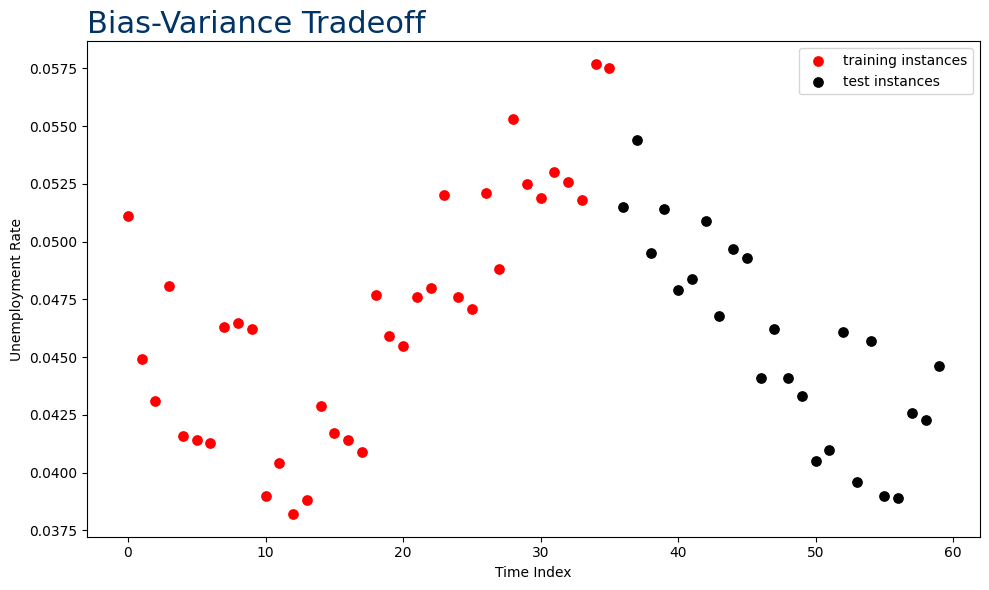

In [8]:
import matplotlib.pyplot as plt

# =========================
# Bias-Variance Tradeoff Plot
# =========================

target = "Unemployment_Rate"
initial_train_size = 36

# Create a time index for visualization
df["Time_Index"] = range(len(df))

# Split based on expanding-window logic
train_df = df.iloc[:initial_train_size]
test_df = df.iloc[initial_train_size:]

plt.figure(figsize=(10, 6))

# Training instances
plt.scatter(
    train_df["Time_Index"],
    train_df[target],
    color="red",
    label="training instances",
    s=45
)

# Test instances
plt.scatter(
    test_df["Time_Index"],
    test_df[target],
    color="black",
    label="test instances",
    s=45
)

plt.title("Bias-Variance Tradeoff", fontsize=22, loc="left", color="#003366")
plt.xlabel("Time Index")
plt.ylabel("Unemployment Rate")
plt.legend()
plt.grid(False)

plt.tight_layout()
plt.show()

Numeric features: ['Year', 'Month', 'Market_Return', 'Market_Volatility', 'GDP_Growth', 'Inflation_Rate', 'Interest_Rate', 'Exchange_Rate_USD', 'Industry_Growth', 'Consumer_Confidence', 'Business_Confidence', 'Time_Index']
Categorical features: ['Risk_Level', 'Business_Cycle']
Degree 1: Training MSE = 0.0000, Test MSE = 0.0000
Degree 2: Training MSE = 0.0000, Test MSE = 0.0001
Degree 3: Training MSE = 0.0000, Test MSE = 0.0000
Degree 4: Training MSE = 0.0000, Test MSE = 0.0003
Degree 5: Training MSE = 0.0000, Test MSE = 0.0003
Degree 6: Training MSE = 0.0000, Test MSE = 0.0023
Degree 7: Training MSE = 0.0000, Test MSE = 0.0027
Degree 8: Training MSE = 0.0000, Test MSE = 0.0196

Best polynomial degree based on test MSE: 1


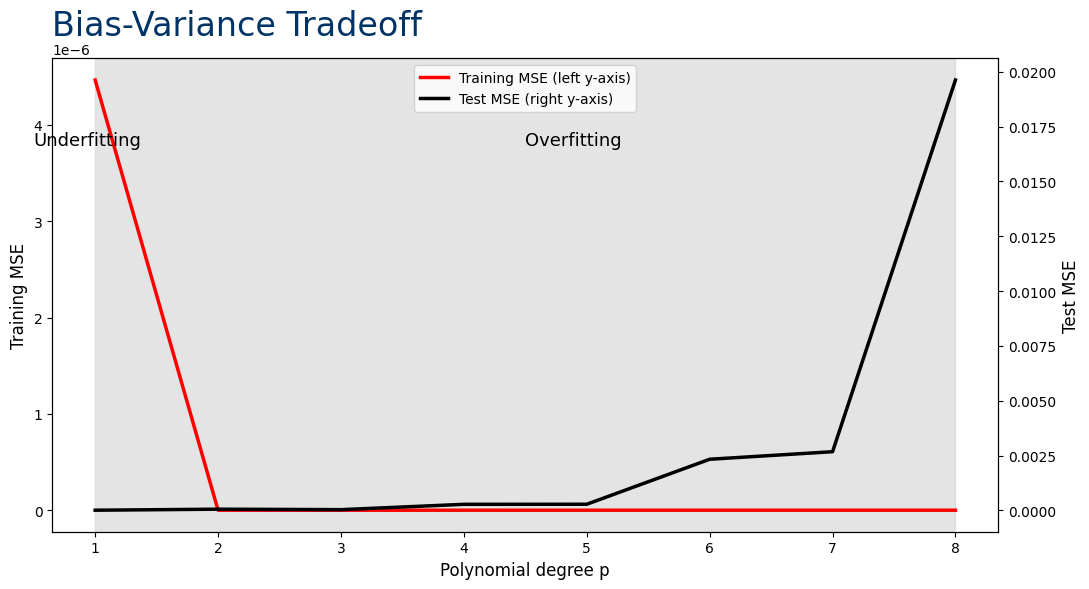

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


# =========================
# 1. Prepare data
# =========================
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

target = "Unemployment_Rate"

X = df.drop(columns=["Date", target])
y = df[target]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


# =========================
# 2. Bias-variance setting
# =========================
initial_train_size = 36

# Because your dataset only has 60 rows, do not make this too high.
# You can try 8 or 10 first.
max_degree = 8

degrees = range(1, max_degree + 1)

training_mse_list = []
test_mse_list = []


# =========================
# 3. Expanding-window evaluation by polynomial degree
# =========================
for degree in degrees:
    
    numeric_transformer = Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False))
    ])

    categorical_transformer = Pipeline(steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    train_mse_each_step = []
    test_error_each_step = []

    for i in range(initial_train_size, len(df)):
        
        X_train = X.iloc[:i]
        y_train = y.iloc[:i]

        X_test = X.iloc[[i]]
        y_test = y.iloc[i]

        # Fit model on expanding training set
        model.fit(X_train, y_train)

        # Training MSE
        y_train_pred = model.predict(X_train)
        train_mse = mean_squared_error(y_train, y_train_pred)
        train_mse_each_step.append(train_mse)

        # One-step-ahead test error
        y_test_pred = model.predict(X_test)[0]
        test_error = (y_test - y_test_pred) ** 2
        test_error_each_step.append(test_error)

    # Average MSE across expanding-window steps
    avg_train_mse = np.mean(train_mse_each_step)
    avg_test_mse = np.mean(test_error_each_step)

    training_mse_list.append(avg_train_mse)
    test_mse_list.append(avg_test_mse)

    print(
        f"Degree {degree}: "
        f"Training MSE = {avg_train_mse:.4f}, "
        f"Test MSE = {avg_test_mse:.4f}"
    )


# =========================
# 4. Find best polynomial degree
# =========================
best_degree = degrees[np.argmin(test_mse_list)]
print(f"\nBest polynomial degree based on test MSE: {best_degree}")


# =========================
# 5. Plot Bias-Variance Tradeoff
# =========================
fig, ax1 = plt.subplots(figsize=(11, 6))

ax2 = ax1.twinx()

# Shaded regions
ax1.axvspan(1, best_degree, color="lightcyan", alpha=0.6)
ax1.axvspan(best_degree, max_degree, color="lightgray", alpha=0.6)

# Lines
ax1.plot(
    list(degrees),
    training_mse_list,
    color="red",
    linewidth=2.5,
    label="Training MSE (left y-axis)"
)

ax2.plot(
    list(degrees),
    test_mse_list,
    color="black",
    linewidth=2.5,
    label="Test MSE (right y-axis)"
)

# Labels
ax1.set_xlabel("Polynomial degree p", fontsize=12)
ax1.set_ylabel("Training MSE", fontsize=12)
ax2.set_ylabel("Test MSE", fontsize=12)

plt.title(
    "Bias-Variance Tradeoff",
    fontsize=24,
    loc="left",
    color="#003366"
)

# Text labels
ax1.text(
    best_degree / 2,
    max(training_mse_list) * 0.85,
    "Underfitting",
    fontsize=13
)

ax1.text(
    best_degree + (max_degree - best_degree) / 2,
    max(training_mse_list) * 0.85,
    "Overfitting",
    fontsize=13
)

# Combine legends from two axes
line1, label1 = ax1.get_legend_handles_labels()
line2, label2 = ax2.get_legend_handles_labels()

ax1.legend(
    line1 + line2,
    label1 + label2,
    loc="upper center"
)

ax1.grid(False)
ax2.grid(False)

plt.tight_layout()
plt.show()